# Decision Tree: Preterm Birth Prediction

## 1. Introduction

### Objective

The objective of this notebook is to develop and evaluate a Decision Tree
classification model to predict preterm birth using the CDC/NCHS 2025
Natality sample.

A preterm birth is defined as a birth occurring before 37 completed
weeks of pregnancy.

The target variable is `preterm_birth`:
- 0: Term birth
- 1: Preterm birth

### Dataset

The model uses the preprocessed training and testing datasets provided
by the Data Preprocessing stage.

- Training dataset: train_preprocessed.csv
- Testing dataset: test_preprocessed.csv

### Methodology

The workflow follows these steps:

1. Load the preprocessed datasets.
2. Separate input features and target.
3. Train a Decision Tree classifier.
4. Generate predictions.
5. Evaluate the model using classification metrics.
6. Visualize and interpret the decision tree.
7. Analyze feature importance.


## 1. Loading the data

In [61]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

import joblib

from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    balanced_accuracy_score,
    matthews_corrcoef,
    average_precision_score,
    RocCurveDisplay,
    PrecisionRecallDisplay
)

train = pd.read_csv("data/train_preprocessed.csv")
test = pd.read_csv("data/test_preprocessed.csv")

print("Training dataset shape:", train.shape)
print("Testing dataset shape:", test.shape)

print("\nTraining columns:")
print(train.columns.tolist())

print("\nFirst rows of training data:")
display(train.head())

Training dataset shape: (8000, 19)
Testing dataset shape: (2000, 19)

Training columns:
['prior_live_births_now_living', 'prior_live_births_now_dead', 'prepregnancy_bmi', 'maternal_age_group', 'maternal_education', 'maternal_education_unknown', 'prepregnancy_diabetes_no', 'prepregnancy_diabetes_unknown', 'prepregnancy_diabetes_yes', 'prepregnancy_hypertension_no', 'prepregnancy_hypertension_unknown', 'prepregnancy_hypertension_yes', 'previous_preterm_birth_no', 'previous_preterm_birth_unknown', 'previous_preterm_birth_yes', 'plurality_singleton', 'plurality_triplets', 'plurality_twins', 'preterm_birth']

First rows of training data:


,prior_live_births_now_living,prior_live_births_now_dead,prepregnancy_bmi,maternal_age_group,maternal_education,maternal_education_unknown,prepregnancy_diabetes_no,prepregnancy_diabetes_unknown,prepregnancy_diabetes_yes,prepregnancy_hypertension_no,prepregnancy_hypertension_unknown,prepregnancy_hypertension_yes,previous_preterm_birth_no,previous_preterm_birth_unknown,previous_preterm_birth_yes,plurality_singleton,plurality_triplets,plurality_twins,preterm_birth
0,-0.860204,-0.11077,-0.208590,-1.110047,-0.799103,0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0
1,-0.210993,-0.11077,0.822926,1.238845,1.092452,0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0
2,-0.210993,-0.11077,-0.571799,-1.110047,-0.168585,0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0
3,-0.860204,-0.11077,-0.935009,-0.327083,-0.168585,0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0
4,-0.860204,-0.11077,-1.152935,-1.110047,-1.429621,0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0


## 2.Understanding the datasets

In [3]:
print("===== TRAINING DATASET =====")
train.info()

print("\nMissing values in training dataset:")
print(train.isna().sum().sum())

print("\n===== TESTING DATASET =====")
test.info()

print("\nMissing values in testing dataset:")
print(test.isna().sum().sum())

print("\nSame columns and order:",
      train.columns.equals(test.columns))

===== TRAINING DATASET =====
<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 19 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   prior_live_births_now_living       8000 non-null   float64
 1   prior_live_births_now_dead         8000 non-null   float64
 2   prepregnancy_bmi                   8000 non-null   float64
 3   maternal_age_group                 8000 non-null   float64
 4   maternal_education                 8000 non-null   float64
 5   maternal_education_unknown         8000 non-null   int64  
 6   prepregnancy_diabetes_no           8000 non-null   float64
 7   prepregnancy_diabetes_unknown      8000 non-null   float64
 8   prepregnancy_diabetes_yes          8000 non-null   float64
 9   prepregnancy_hypertension_no       8000 non-null   float64
 10  prepregnancy_hypertension_unknown  8000 non-null   float64
 11  prepregnancy_hypertension_yes      800

## 3. Checking the Target Distribution

In this section, we examine the distribution of the target variable, `preterm_birth`.

The target variable contains two classes:

- **0:** Term birth
- **1:** Preterm birth

Understanding the distribution of these classes is important because an imbalanced dataset can affect the learning process and the evaluation of the classification model.

Training target distribution:
preterm_birth
0    7150
1     850
Name: count, dtype: int64

Training target percentages:
preterm_birth
0    89.375
1    10.625
Name: proportion, dtype: float64

Testing target distribution:
preterm_birth
0    1788
1     212
Name: count, dtype: int64


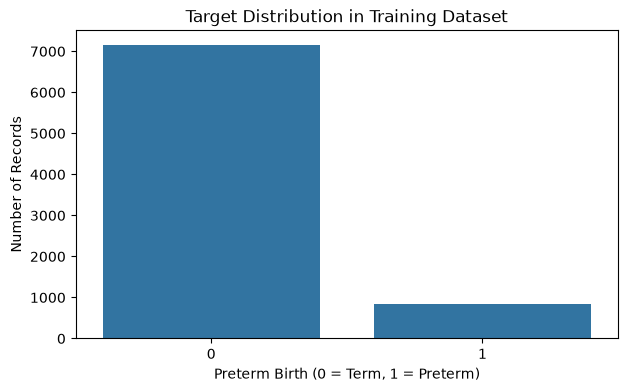

In [46]:
TARGET = "preterm_birth"

print("Training target distribution:")
print(train[TARGET].value_counts())

print("\nTraining target percentages:")
print(train[TARGET].value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(test[TARGET].value_counts())

# Visualization
plt.figure(figsize=(7, 4))

sns.countplot(data=train, x=TARGET)

plt.title("Target Distribution in Training Dataset")
plt.xlabel("Preterm Birth (0 = Term, 1 = Preterm)")
plt.ylabel("Number of Records")
plt.savefig("figures/target_distribution.png",
            dpi=300, bbox_inches="tight")
plt.show()

<span style="color:#2874A6;">We calculate the number and percentage of observations belonging to each target class in both datasets.

<span style="color:#2874A6;">A count plot is also generated to visualize the distribution of term and preterm births in the training dataset.

<span style="color:#2874A6;">This visualization helps identify whether the target variable is imbalanced, which is particularly important when interpreting metrics such as accuracy, precision, recall, and F1-score.

## 4. Preparing the Features and Target

In this step, we separate the input features from the target variable.

The input features, represented by `X`, contain the information used by the model to make predictions. The target variable, represented by `y`, contains the actual birth outcome.

We perform this separation independently for the training and testing datasets.

In [6]:
X_train = train.drop(columns=[TARGET])
y_train = train[TARGET]

X_test = test.drop(columns=[TARGET])
y_test = test[TARGET]

X_train = X_train.drop(columns=["split"], errors="ignore")
X_test = X_test.drop(columns=["split"], errors="ignore")

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

# Check feature consistency
assert X_train.columns.equals(X_test.columns)

print("\nTarget classes:", sorted(y_train.unique()))

# Check target separation
assert TARGET not in X_train.columns
assert TARGET not in X_test.columns

print("\nFeatures and target separated successfully.")

X_train shape: (8000, 18)
X_test shape: (2000, 18)
y_train shape: (8000,)
y_test shape: (2000,)

Target classes: [np.int64(0), np.int64(1)]

Features and target separated successfully.


## 5. Training the Decision Tree Models

In this section, we train and evaluate two Decision Tree configurations.

The first model is a baseline Decision Tree with default hyperparameters. The second model is a regularized Decision Tree with restrictions on its complexity and class weighting.

Comparing these configurations allows us to study the effect of model complexity and class imbalance on predictive performance.

### 5.1. Baseline Decision Tree

The baseline model is trained using the default Decision Tree configuration, with only the random state specified to ensure reproducibility.

No restrictions are imposed on the tree depth or the minimum number of samples required to split a node or create a leaf.

This model provides a reference point for evaluating the performance of the regularized model.

In [9]:
# Create the Baseline Decision Tree model

baseline_tree = DecisionTreeClassifier(
    random_state=42
)

baseline_tree.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

<span style="color:#2874A6;">The `DecisionTreeClassifier` is initialized and fitted using the training features and their corresponding target values.

<span style="color:#2874A6;">During training, the algorithm learns decision rules that separate the observations into term and preterm birth classes.

In [10]:

print("Tree depth:", baseline_tree.get_depth())
print("Number of leaves:", baseline_tree.get_n_leaves())

Tree depth: 37
Number of leaves: 1468


<span style="color:#2874A6;">After training, we examine the structure of the baseline Decision Tree.

<span style="color:#2874A6;">The tree depth represents the maximum number of decision levels from the root to a leaf. The number of leaves represents the terminal nodes where final predictions are made.

<span style="color:#2874A6;">These values provide an initial indication of the complexity of the trained model.

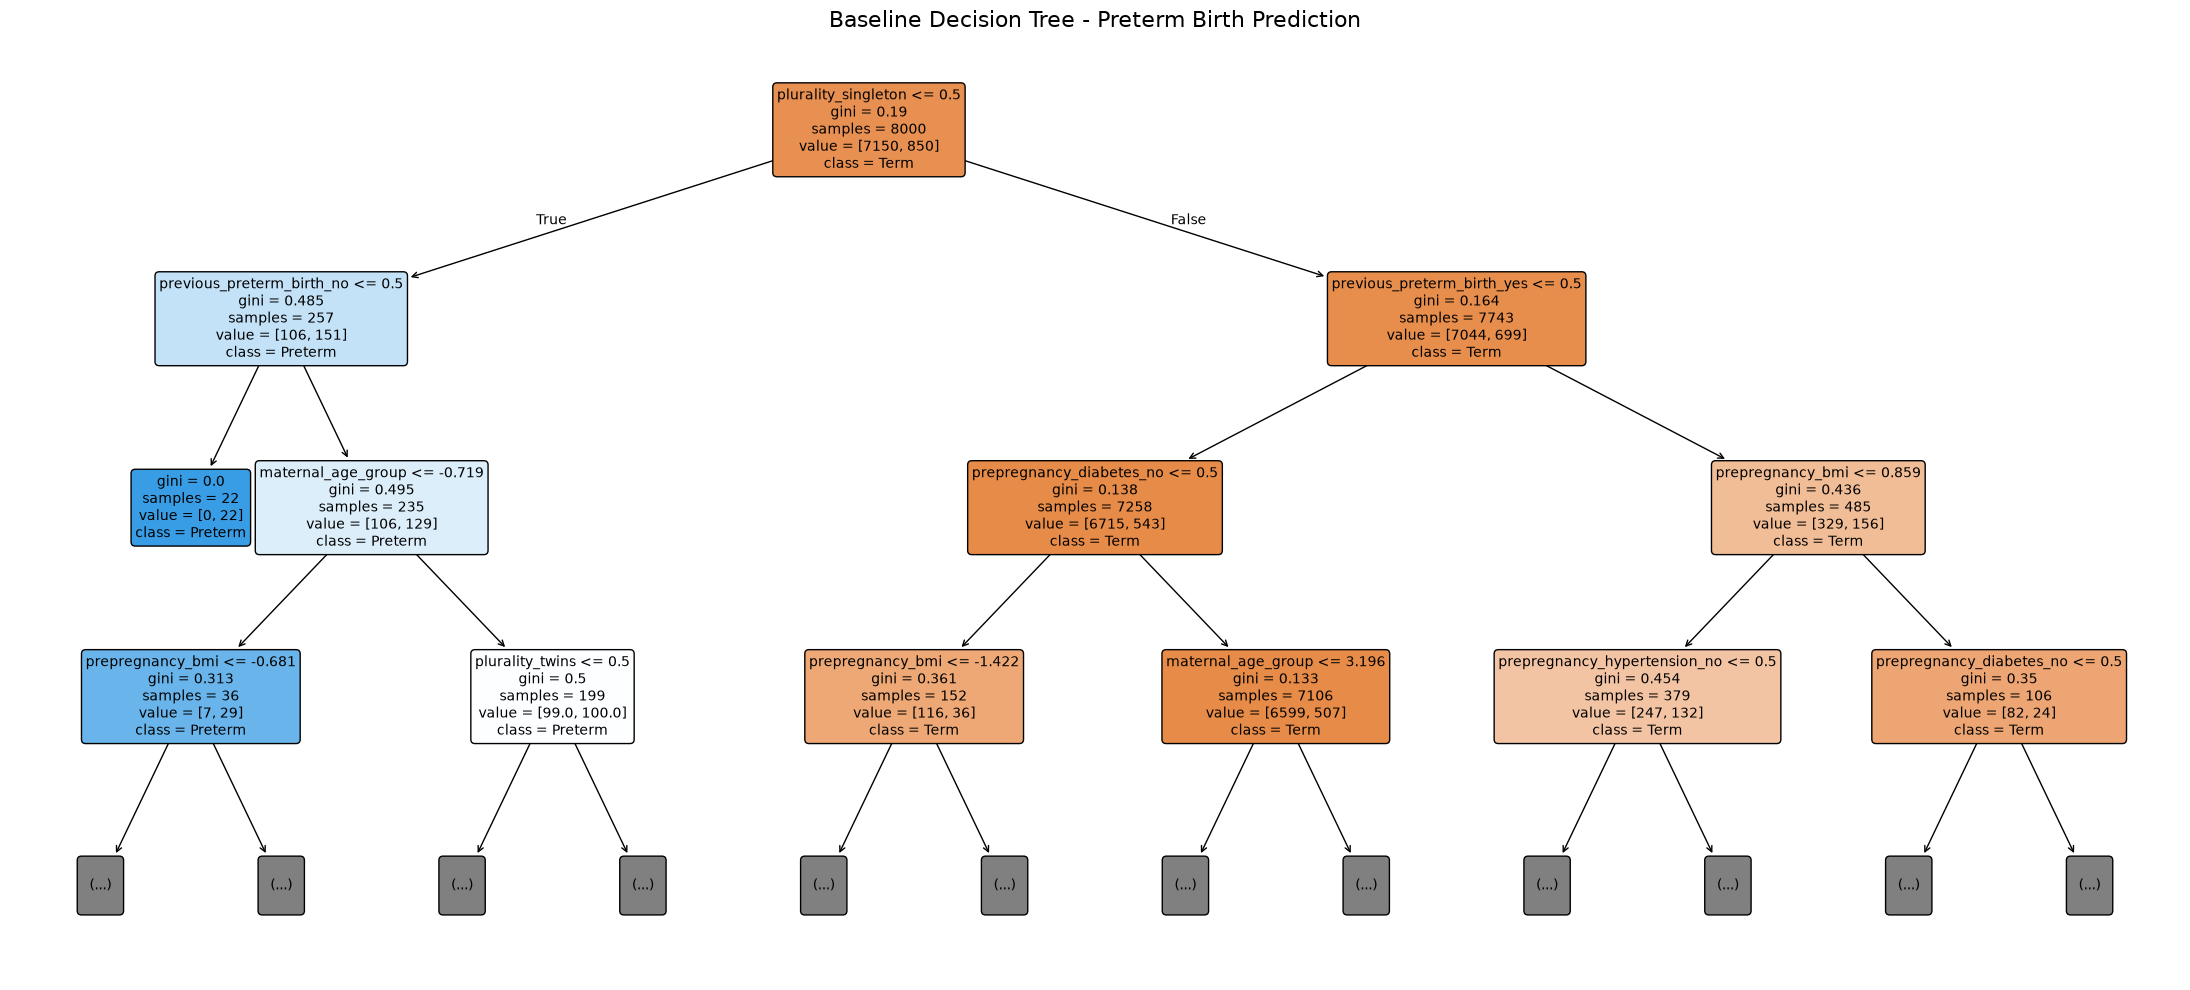

In [65]:
plt.figure(figsize=(22, 10))

plot_tree(
    baseline_tree,
    feature_names=X_train.columns,
    class_names=["Term", "Preterm"],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3
)

plt.title(
    "Baseline Decision Tree - Preterm Birth Prediction",
    fontsize=16
)

plt.tight_layout()
plt.savefig("figures/Baseline Decision Tree - Preterm Birth Prediction.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [20]:

y_pred = baseline_tree.predict(X_test)
positive_index = list(baseline_tree.classes_).index(1)
y_proba = baseline_tree.predict_proba(X_test)[:, positive_index]

# Calculate metrics
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    pos_label=1,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_proba
)

# Display results
print("=" * 45)
print("BASELINE DECISION TREE - EVALUATION")
print("=" * 45)

print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
print(f"ROC-AUC:   {roc_auc:.4f}")

BASELINE DECISION TREE - EVALUATION
Accuracy:  0.8480
Precision: 0.2982
Recall:    0.3208
F1-score:  0.3091
ROC-AUC:   0.6153


<span style="color:#2874A6;">The trained baseline model is used to predict the birth outcome for the testing dataset.

<span style="color:#2874A6;">We also obtain the predicted probability of the positive class (preterm birth), which is required to calculate the ROC-AUC score.

<span style="color:#2874A6;">The model is evaluated using the following metrics:

- **Accuracy:** the proportion of correctly classified observations.
- **Precision:** the proportion of predicted preterm births that are actually preterm.
- **Recall:** the proportion of actual preterm births correctly identified by the model.
- **F1-score:** the harmonic mean of precision and recall.
- **ROC-AUC:** measures the model's ability to distinguish between the two classes across different classification thresholds.

<span style="color:#2874A6;">Since identifying preterm births is particularly important, recall for class 1 deserves special attention.

In [21]:
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Term", "Preterm"],
    zero_division=0
))

              precision    recall  f1-score   support

        Term       0.92      0.91      0.91      1788
     Preterm       0.30      0.32      0.31       212

    accuracy                           0.85      2000
   macro avg       0.61      0.62      0.61      2000
weighted avg       0.85      0.85      0.85      2000



<span style="color:#2874A6;">The classification report provides a detailed evaluation of the baseline model for each target class.

<span style="color:#2874A6;">It displays precision, recall, and F1-score separately for term births and preterm births, together with macro and weighted averages.

<span style="color:#2874A6;">This report helps us understand whether the model performs similarly for both classes or favors the majority class.

In [24]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay
)
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=[0, 1]
)

print("Confusion Matrix:")
print("[[TN, FP]")
print(" [FN, TP]]")
print(cm)

Confusion Matrix:
[[TN, FP]
 [FN, TP]]
[[1628  160]
 [ 144   68]]


<span style="color:#2874A6;">The confusion matrix summarizes the classification results by comparing the actual labels with the predicted labels.

<span style="color:#2874A6;">It contains four values:

- **True Negatives (TN):** term births correctly predicted as term.
- **False Positives (FP):** term births incorrectly predicted as preterm.
- **False Negatives (FN):** preterm births incorrectly predicted as term.
- **True Positives (TP):** preterm births correctly predicted as preterm.

<span style="color:#2874A6;">False negatives are particularly important in this project because they represent preterm births that the model fails to identify.

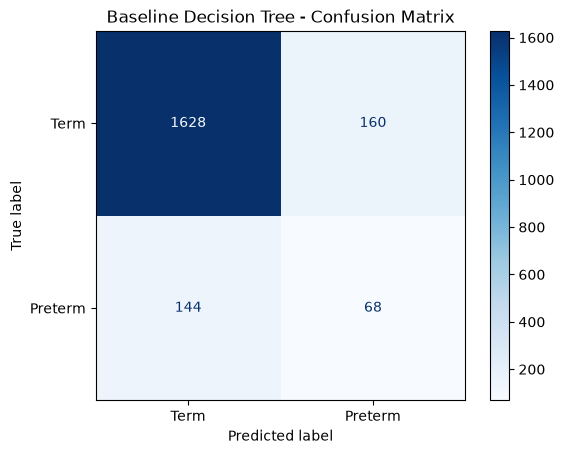

In [47]:
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Term", "Preterm"]
)

disp.plot(cmap="Blues")

plt.title("Baseline Decision Tree - Confusion Matrix")
plt.savefig("figures/baseline_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

<span style="color:#2874A6;">The confusion matrix is displayed as a heatmap to make the classification results easier to interpret.

<span style="color:#2874A6;">The visualization helps identify the number of correct and incorrect predictions for each class and highlights the types of classification errors made by the baseline model.

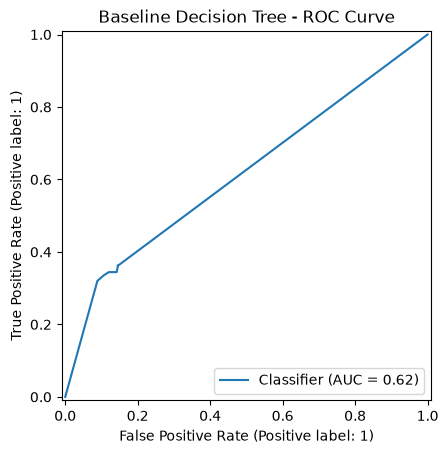

In [48]:
from sklearn.metrics import RocCurveDisplay

RocCurveDisplay.from_predictions(
    y_test,
    y_proba
)

plt.title("Baseline Decision Tree - ROC Curve")
plt.savefig("figures/baseline_roc_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()

<span style="color:#2874A6;">The Receiver Operating Characteristic (ROC) curve illustrates the relationship between the True Positive Rate and the False Positive Rate at different classification thresholds.

<span style="color:#2874A6;">The Area Under the Curve (ROC-AUC) provides a single measure of the model's ability to distinguish between term and preterm births.

<span style="color:#2874A6;">A higher ROC-AUC generally indicates better class discrimination.

In [27]:
from sklearn.metrics import balanced_accuracy_score

tn, fp, fn, tp = cm.ravel()

specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred
)

print("Specificity:", round(specificity, 4))
print("Balanced Accuracy:", round(balanced_accuracy, 4))

Specificity: 0.9105
Balanced Accuracy: 0.6156


<span style="color:#2874A6;">In addition to the previous metrics, we calculate specificity and balanced accuracy.</span>

<span style="color:#2874A6;">- **Specificity:** measures the proportion of actual term births correctly identified by the model.<br><br>
<span style="color:#2874A6;">- **Balanced Accuracy:** calculates the average recall obtained across the two classes.</span>

<span style="color:#2874A6;">These metrics are useful when the target distribution is imbalanced because they provide information that ordinary accuracy alone may not reveal.</span>

In [28]:
train_accuracy = baseline_tree.score(
    X_train,
    y_train
)

test_accuracy = baseline_tree.score(
    X_test,
    y_test
)

print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))

print(
    "Difference:",
    round(train_accuracy - test_accuracy, 4)
)

Training Accuracy: 0.9789
Testing Accuracy: 0.848
Difference: 0.1309


<span style="color:#2874A6;">We compare the model's accuracy on the training dataset with its accuracy on the testing dataset.

<span style="color:#2874A6;">A large difference between these two values may indicate overfitting, meaning that the model performs well on the training observations but generalizes less effectively to unseen data.

<span style="color:#2874A6;">This comparison helps us assess the generalization ability of the baseline Decision Tree.

In [38]:
import pandas as pd

# Calculate feature importance
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": baseline_tree.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
2,prepregnancy_bmi,0.459140
3,maternal_age_group,0.138090
0,prior_live_births_now_living,0.113851
4,maternal_education,0.107926
15,plurality_singleton,0.093658
14,previous_preterm_birth_yes,0.042176
6,prepregnancy_diabetes_no,0.008567
12,previous_preterm_birth_no,0.008290
1,prior_live_births_now_dead,0.007313
9,prepregnancy_hypertension_no,0.005417


<span style="color:#2874A6;">We calculate the feature importance scores provided by the trained baseline Decision Tree.

<span style="color:#2874A6;">These scores indicate how much each feature contributes to reducing impurity throughout the tree.

<span style="color:#2874A6;">The features are sorted in descending order to identify those that have the greatest influence on the model's predictions.

<span style="color:#2874A6;">Feature importance indicates predictive contribution within this model; it does not establish a causal relationship with preterm birth.

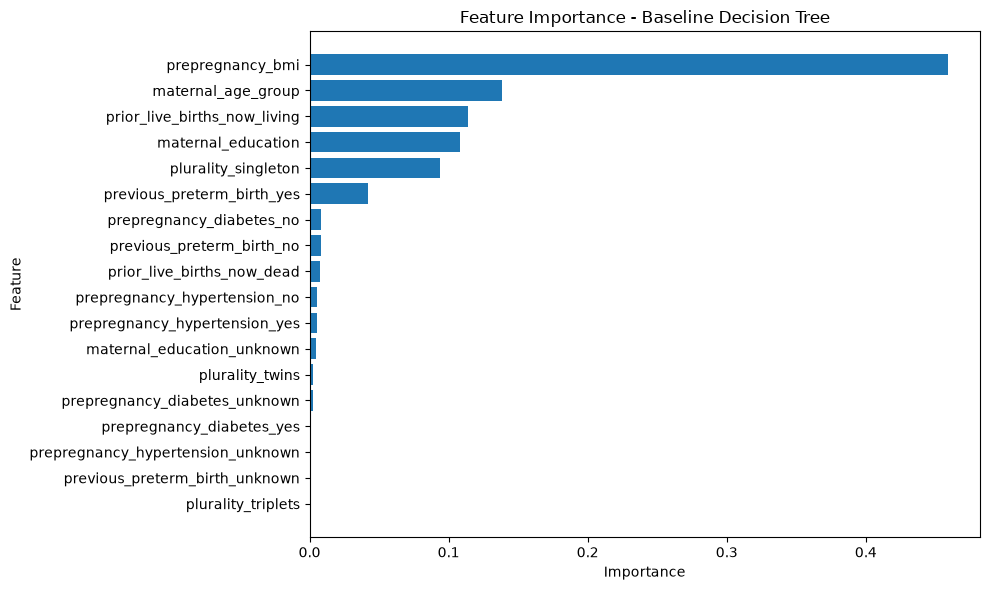

In [49]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Baseline Decision Tree")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("figures/baseline_feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()

<span style="color:#2874A6;">The feature importance scores are displayed using a horizontal bar chart.

<span style="color:#2874A6;">This visualization makes it easier to compare the relative contribution of the input features and identify the most influential variables used by the baseline Decision Tree.

### 5.2. Regularized Decision Tree

In this section, we train a second Decision Tree model with additional constraints to control its complexity.

The model uses the following hyperparameters:

- `max_depth=5`: limits the maximum depth of the tree.
- `min_samples_split=20`: requires at least 20 samples to split an internal node.
- `min_samples_leaf=10`: requires at least 10 samples in each leaf.
- `class_weight="balanced"`: adjusts class weights inversely according to their frequencies.

These settings aim to reduce overfitting and address the imbalance between term and preterm birth observations.

In [60]:
# Create the Tuned Decision Tree model

regularized_tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_split=20,
    min_samples_leaf=10,
    class_weight="balanced",
    random_state=42
)

# Train the model
regularized_tree.fit(X_train, y_train)


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",20
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",10
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"class_weight class_weight: dict, list of dict or ""balanced"", default=NoneWeights associated with classes in the form ``{class_label: weight}``.If None, all classes are supposed to have weight one. Formulti-output problems, a list of dicts can be provided in the sameorder as the columns of y.Note that for multioutput (including multilabel) weights should bedefined for each class of every column in its own dict. For example,for four-class multilabel classification weights should be[{0: 1, 1: 1}, {0: 1, 1: 5}, {0: 1, 1: 1}, {0: 1, 1: 1}] instead of[{1:1}, {2:5}, {3:1}, {4:1}].The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``For multi-output, the weights of each column of y will be multiplied.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified.",'balanced'
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_fe

<span style="color:#2874A6;">The regularized Decision Tree is initialized with the selected hyperparameters and fitted using the same training dataset as the baseline model.

<span style="color:#2874A6;">Using the same training data allows us to compare both models under consistent experimental conditions.

In [59]:
print("Tree depth:", regularized_tree.get_depth())
print("Number of leaves:", regularized_tree.get_n_leaves())

Tree depth: 5
Number of leaves: 22


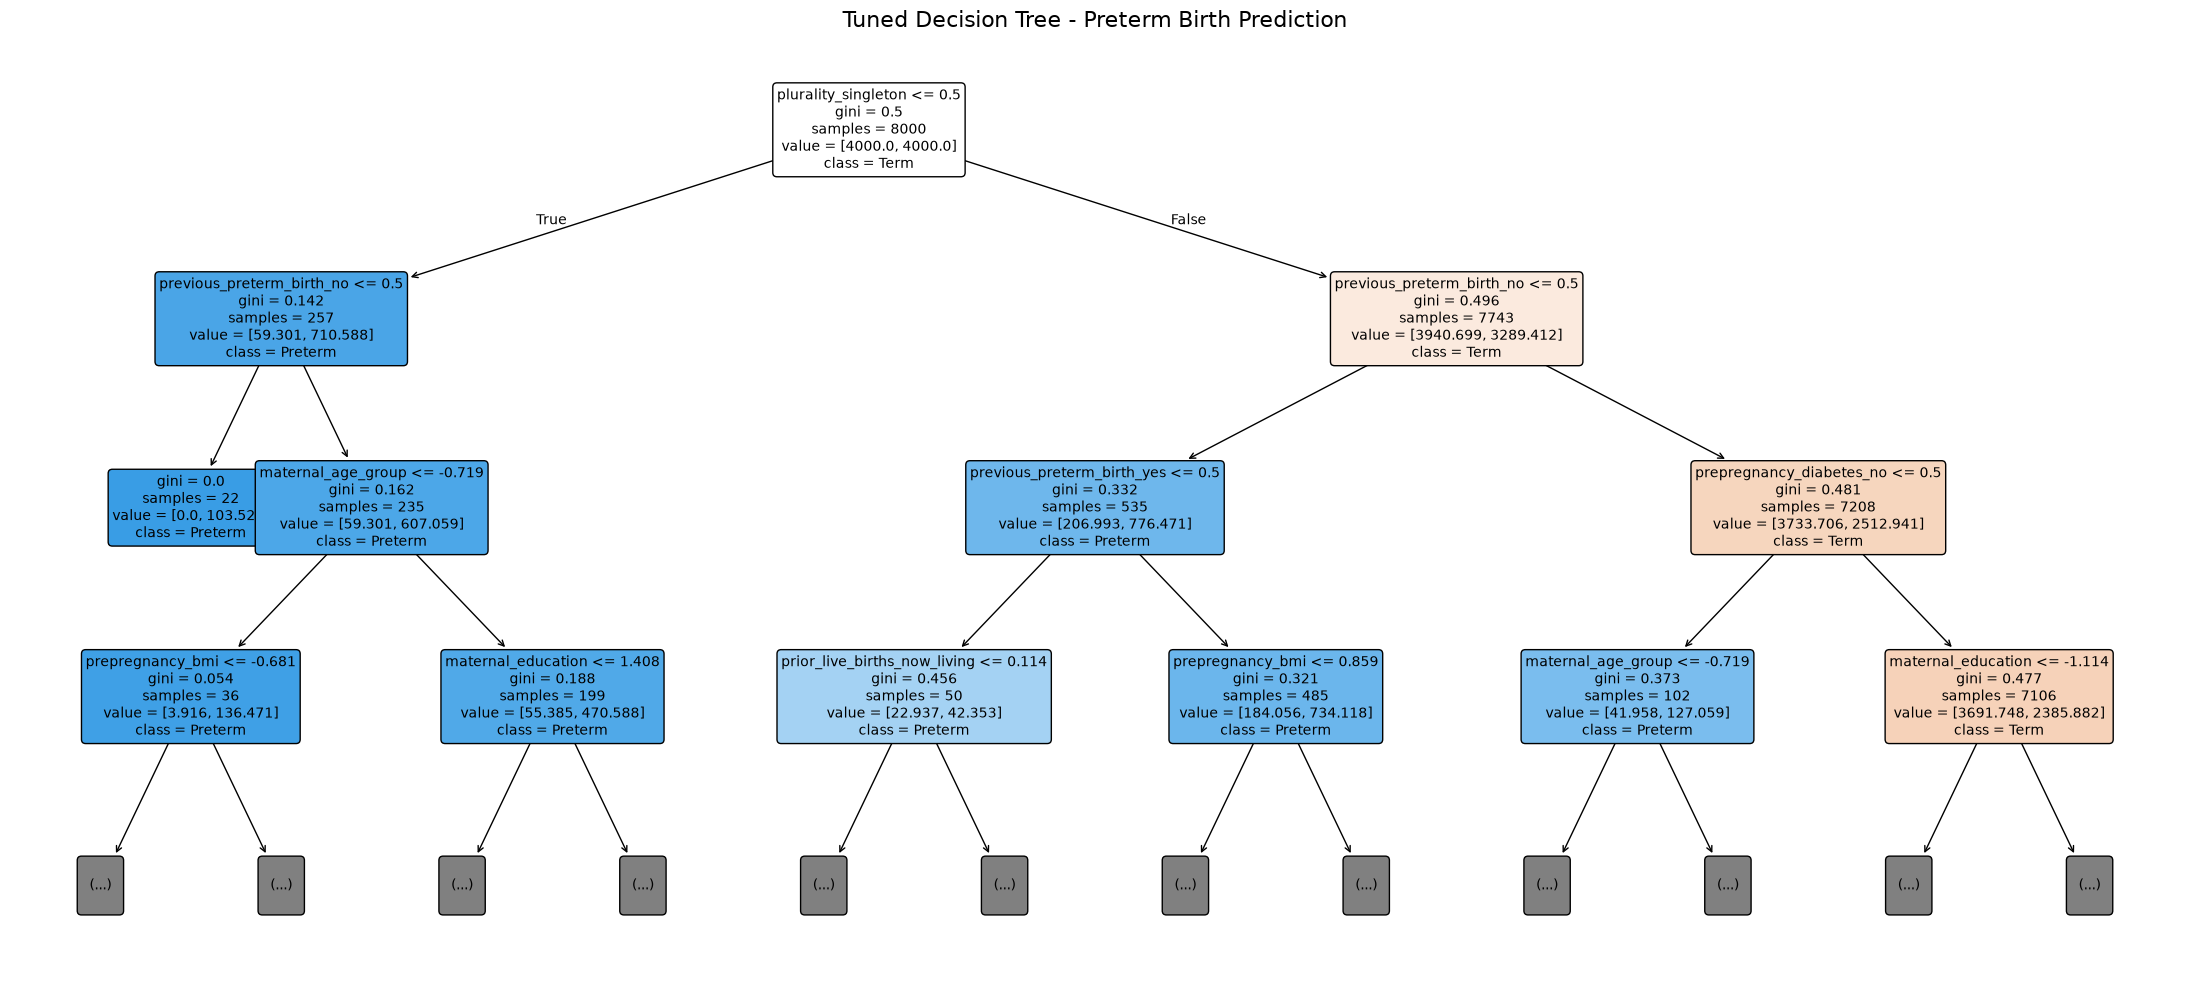

In [63]:
plt.figure(figsize=(22, 10))

plot_tree(
    regularized_tree,
    feature_names=X_train.columns,
    class_names=["Term", "Preterm"],
    filled=True,
    rounded=True,
    fontsize=10,
    max_depth=3
)

plt.title(
    "Tuned Decision Tree - Preterm Birth Prediction",
    fontsize=16
)

plt.tight_layout()
plt.savefig("figures/Tuned Decision Tree - Preterm Birth Prediction.png",
            dpi=300, bbox_inches="tight")
plt.show()

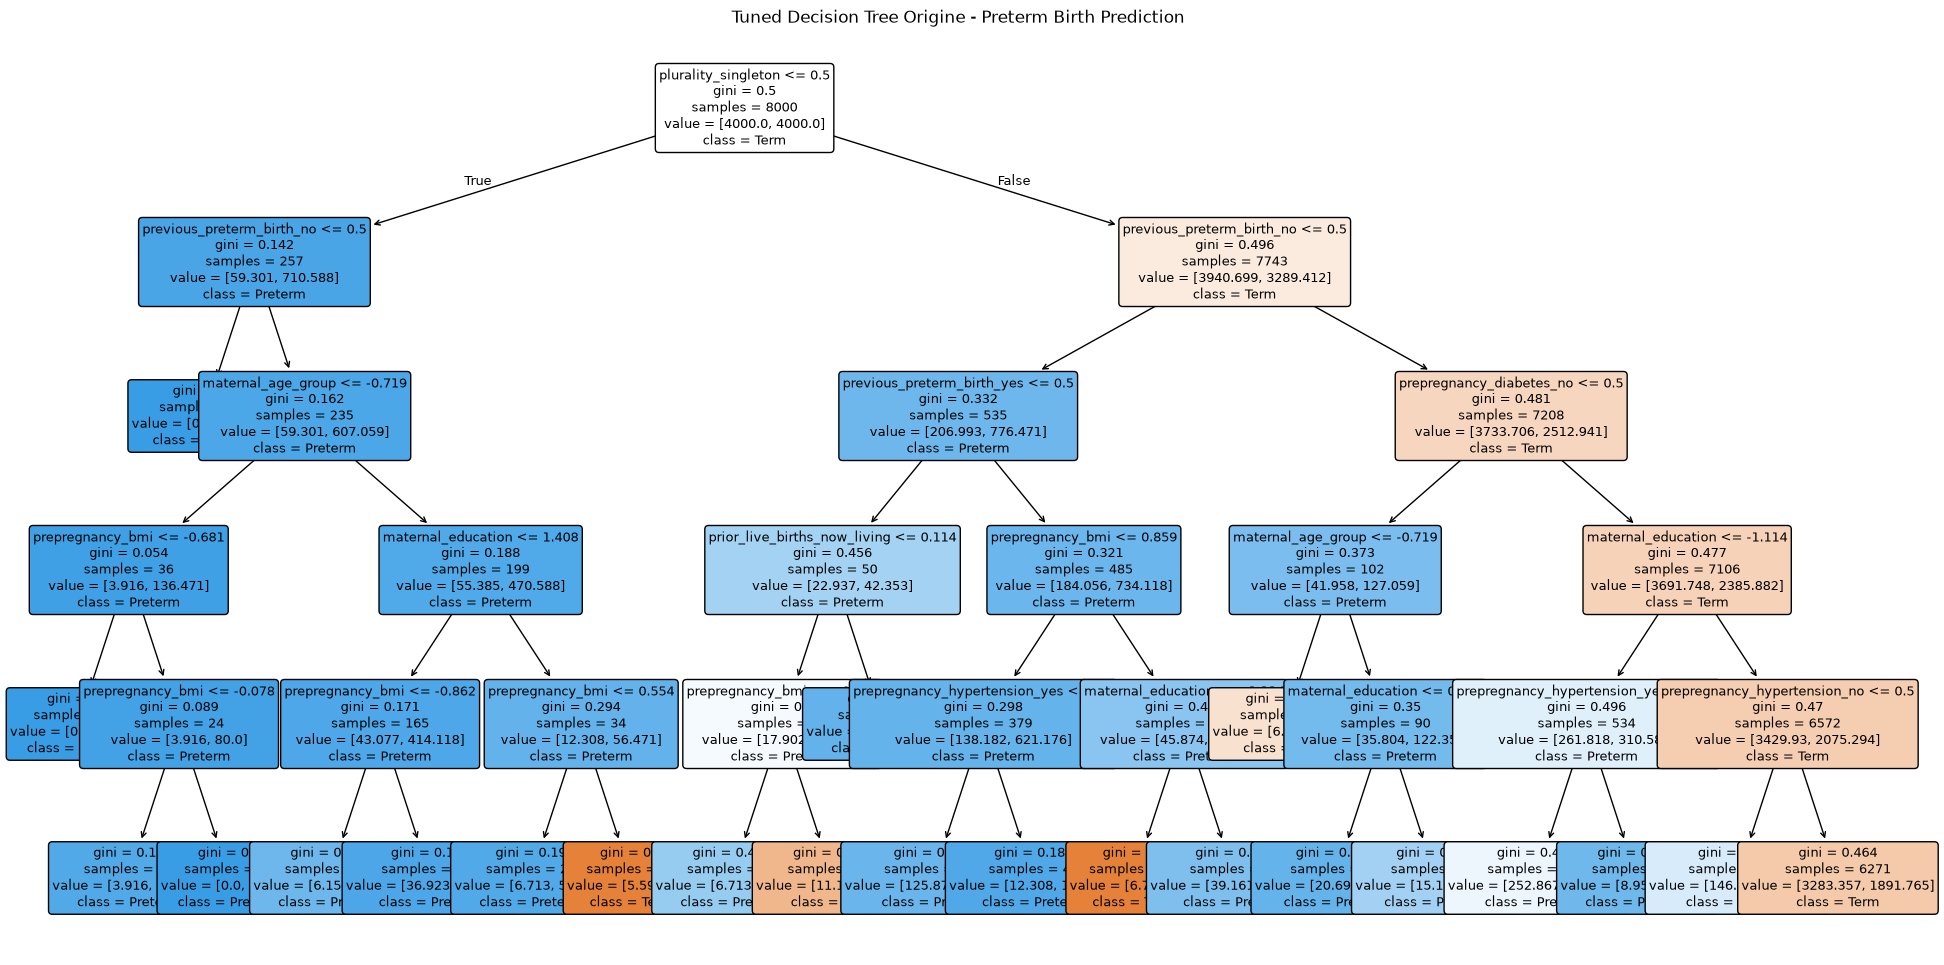

In [64]:
plt.figure(figsize=(24, 12))

plot_tree(
    regularized_tree,
    feature_names=X_train.columns,
    class_names=["Term", "Preterm"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title("Tuned Decision Tree Origine - Preterm Birth Prediction")
plt.savefig("figures/Tuned Decision Tree Origine - Preterm Birth Prediction.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [30]:
# Predict classes
y_pred_reg = regularized_tree.predict(X_test)
positive_index = list(regularized_tree.classes_).index(1)

y_proba_reg = regularized_tree.predict_proba(X_test)[:, positive_index]
# Calculate metrics
accuracy_reg = accuracy_score(y_test, y_pred_reg)

precision_reg = precision_score(
    y_test,
    y_pred_reg,
    pos_label=1,
    zero_division=0
)

recall_reg = recall_score(
    y_test,
    y_pred_reg,
    pos_label=1,
    zero_division=0
)

f1_reg = f1_score(
    y_test,
    y_pred_reg,
    pos_label=1,
    zero_division=0
)

roc_auc_reg = roc_auc_score(
    y_test,
    y_proba_reg
)

print("=" * 45)
print("REGULARIZED DECISION TREE - EVALUATION")
print("=" * 45)

print(f"Accuracy:  {accuracy_reg:.4f}")
print(f"Precision: {precision_reg:.4f}")
print(f"Recall:    {recall_reg:.4f}")
print(f"F1-score:  {f1_reg:.4f}")
print(f"ROC-AUC:   {roc_auc_reg:.4f}")

REGULARIZED DECISION TREE - EVALUATION
Accuracy:  0.7930
Precision: 0.2694
Recall:    0.5566
F1-score:  0.3631
ROC-AUC:   0.7130


In [31]:
print(classification_report(
    y_test,
    y_pred_reg,
    labels=[0, 1],
    target_names=["Term", "Preterm"],
    zero_division=0
))

              precision    recall  f1-score   support

        Term       0.94      0.82      0.88      1788
     Preterm       0.27      0.56      0.36       212

    accuracy                           0.79      2000
   macro avg       0.60      0.69      0.62      2000
weighted avg       0.87      0.79      0.82      2000



<span style="color:#2874A6;">The classification report provides class-specific precision, recall, and F1-score for the regularized Decision Tree.

<span style="color:#2874A6;">By comparing these results with the baseline classification report, we can determine whether regularization improves the identification of preterm births or changes the model's performance on term births.

Regularized Decision Tree - Confusion Matrix
[[1468  320]
 [  94  118]]


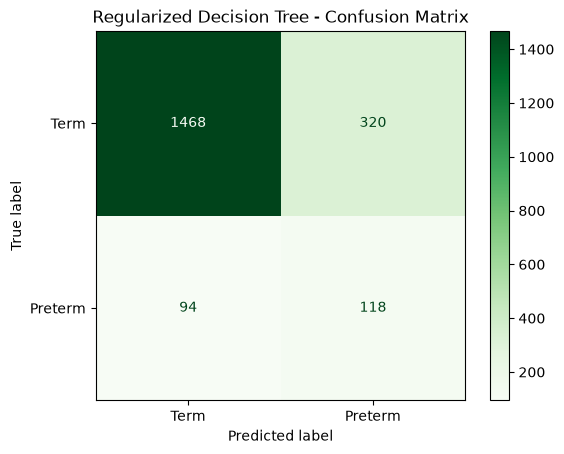

In [50]:
cm_reg = confusion_matrix(
    y_test,
    y_pred_reg,
    labels=[0, 1]
)

print("Regularized Decision Tree - Confusion Matrix")
print(cm_reg)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_reg,
    display_labels=["Term", "Preterm"]
)

disp.plot(cmap="Greens")

plt.title("Regularized Decision Tree - Confusion Matrix")
plt.savefig("figures/regularized_confusion_matrix.png",
            dpi=300, bbox_inches="tight")
plt.show()

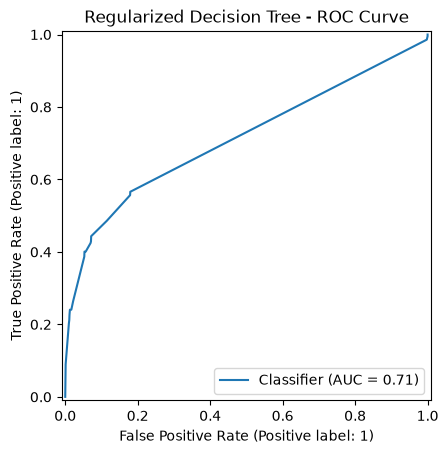

In [51]:
RocCurveDisplay.from_predictions(
    y_test,
    y_proba_reg
)

plt.title("Regularized Decision Tree - ROC Curve")
plt.savefig("figures/regularized_roc_curve.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [34]:
tn_reg, fp_reg, fn_reg, tp_reg = cm_reg.ravel()

specificity_reg = (
    tn_reg / (tn_reg + fp_reg)
    if (tn_reg + fp_reg) > 0
    else 0
)

balanced_accuracy_reg = balanced_accuracy_score(
    y_test,
    y_pred_reg
)

print("Specificity:", round(specificity_reg, 4))
print("Balanced Accuracy:", round(balanced_accuracy_reg, 4))

Specificity: 0.821
Balanced Accuracy: 0.6888


In [35]:
train_accuracy_reg = regularized_tree.score(
    X_train,
    y_train
)

test_accuracy_reg = regularized_tree.score(
    X_test,
    y_test
)

print("Training Accuracy:", round(train_accuracy_reg, 4))
print("Testing Accuracy:", round(test_accuracy_reg, 4))

print(
    "Difference:",
    round(train_accuracy_reg - test_accuracy_reg, 4)
)

Training Accuracy: 0.796
Testing Accuracy: 0.793
Difference: 0.003


In [36]:
import pandas as pd

importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": regularized_tree.feature_importances_
})

importance_df = importance_df.sort_values(
    by="Importance",
    ascending=False
)

display(importance_df)

,Feature,Importance
15,plurality_singleton,0.437819
12,previous_preterm_birth_no,0.368066
6,prepregnancy_diabetes_no,0.060946
4,maternal_education,0.054838
9,prepregnancy_hypertension_no,0.032325
2,prepregnancy_bmi,0.021924
11,prepregnancy_hypertension_yes,0.010339
3,maternal_age_group,0.005288
0,prior_live_births_now_living,0.004470
14,previous_preterm_birth_yes,0.003985


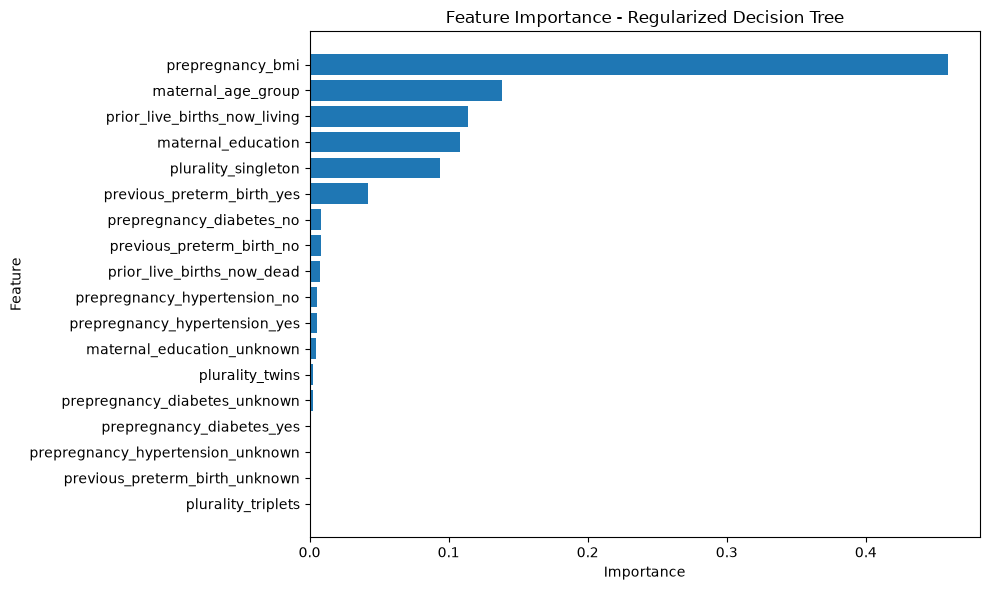

In [52]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df["Feature"],
    importance_df["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance - Regularized Decision Tree")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig("figures/regularized_feature_importance.png",
            dpi=300, bbox_inches="tight")
plt.show()

### 5.3. Comparison Between the Two Models

In this section, we compare the baseline and regularized Decision Tree models using the same testing dataset.

The comparison focuses on predictive performance, particularly the ability to identify preterm births, as well as the models' complexity and generalization ability.

Accuracy alone is not sufficient to select the best model because the target variable is imbalanced. Therefore, recall, F1-score, ROC-AUC, specificity, and balanced accuracy are also considered.

In [45]:
# Predictions
y_pred_baseline = baseline_tree.predict(X_test)
y_pred_tuned = regularized_tree.predict(X_test)

# Compare accuracy
print("BASELINE DECISION TREE")
print("Accuracy:", accuracy_score(y_test, y_pred_baseline))

print("\nTUNED DECISION TREE")
print("Accuracy:", accuracy_score(y_test, y_pred_tuned))

BASELINE DECISION TREE
Accuracy: 0.848

TUNED DECISION TREE
Accuracy: 0.793


<span style="color:#2874A6;">We generate predictions using both trained models on the same testing dataset.

<span style="color:#2874A6;">Their accuracy scores are then calculated and displayed to provide an initial comparison of their overall classification performance.

<span style="color:#2874A6;">However, accuracy should not be used as the only criterion for selecting the final model, especially because preterm births represent the minority class.</span>

In [40]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "Specificity",
        "Balanced Accuracy"
    ],

    "Baseline Decision Tree": [
        accuracy,
        precision,
        recall,
        f1,
        roc_auc,
        specificity,
        balanced_accuracy
    ],

    "Regularized Decision Tree": [
        accuracy_reg,
        precision_reg,
        recall_reg,
        f1_reg,
        roc_auc_reg,
        specificity_reg,
        balanced_accuracy_reg
    ]
})

display(results.round(4))

,Metric,Baseline Decision Tree,Regularized Decision Tree
0,Accuracy,0.8480,0.7930
1,Precision,0.2982,0.2694
2,Recall,0.3208,0.5566
3,F1-score,0.3091,0.3631
4,ROC-AUC,0.6153,0.7130
5,Specificity,0.9105,0.8210
6,Balanced Accuracy,0.6156,0.6888


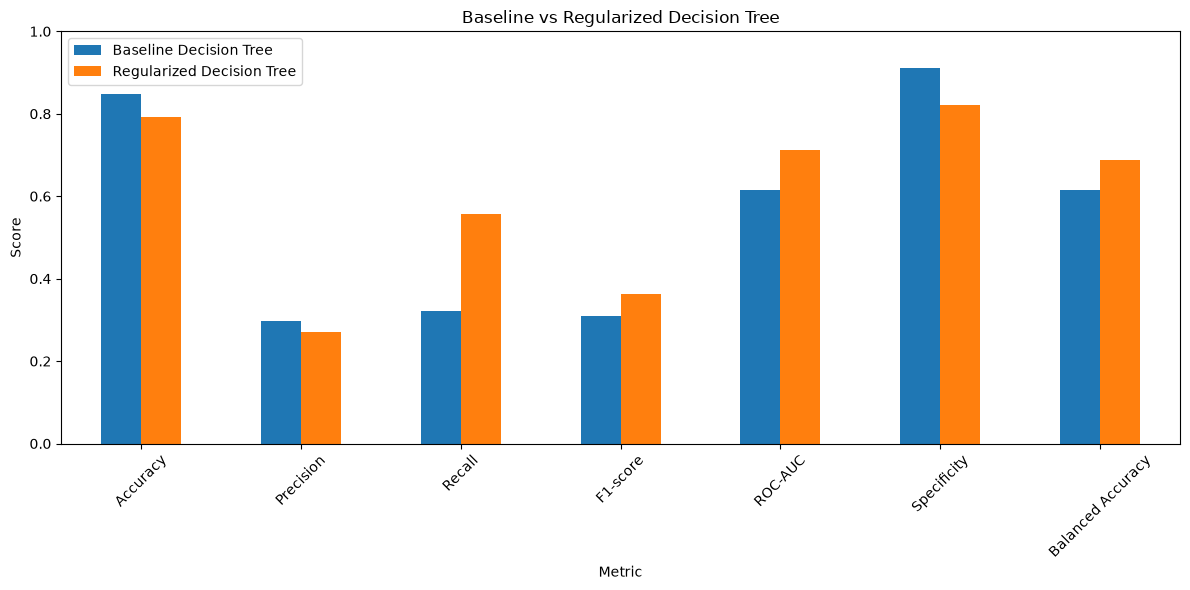

In [53]:
comparison_plot = results.set_index("Metric")

comparison_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Baseline vs Regularized Decision Tree")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.savefig("figures/model_comparison.png",
            dpi=300, bbox_inches="tight")
plt.show()

In [42]:
results.to_csv(
    "decision_tree_metrics.csv",
    index=False
)

print("Metrics saved successfully!")

Metrics saved successfully!


<span style="color:#2874A6;">
Saving the evaluation metrics makes it possible to reuse the results in the project report and compare the Decision Tree models with other machine learning approaches.</span>

In [43]:
import joblib

joblib.dump(
    baseline_tree,
    "baseline_decision_tree.joblib"
)

joblib.dump(
    regularized_tree,
    "regularized_decision_tree.joblib"
)

print("Both models saved successfully!")

Both models saved successfully!


## 6. Conclusion

Two Decision Tree configurations were developed and evaluated: a baseline model and a regularized model.

The baseline model achieved a higher accuracy of 84.80%. However, its recall for preterm births was only 32.08%, meaning that it failed to identify a large proportion of actual preterm cases.

The regularized Decision Tree achieved a lower accuracy of 79.30%, but improved the recall to 55.66%. It also obtained better F1-score, ROC-AUC, and balanced accuracy values.

Furthermore, the regularized model showed a much smaller difference between training and testing accuracy, suggesting better generalization and reduced overfitting.

Since identifying preterm births is a major objective of this project, the regularized Decision Tree is selected as the preferred model.

However, its recall still indicates that some preterm births remain undetected. Further improvements and evaluation would therefore be necessary before considering any real-world clinical application.

## 7.Note:

This project implements the CART (Classification and Regression Trees) algorithm using Scikit-learn's DecisionTreeClassifier. Two configurations are evaluated: a baseline Decision Tree and a regularized Decision Tree.